Reviews loaded: 568454
After removing neutral reviews: 525814
Sentiment
positive    0.843981
negative    0.156019
Name: proportion, dtype: float64


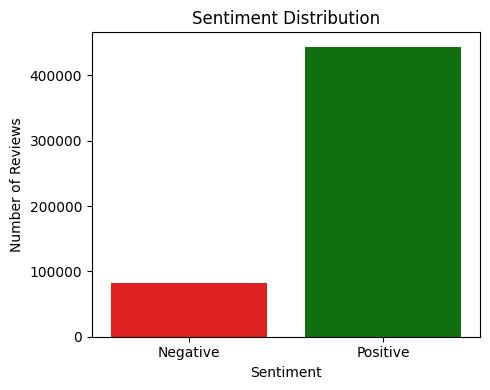

Train: 420651 | Test: 105163
Baseline (always positive) accuracy: 0.844

=== BoW + MultinomialNB ===
              precision    recall  f1-score   support

    Negative      0.768     0.704     0.735     16407
    Positive      0.946     0.961     0.953     88756

    accuracy                          0.921    105163
   macro avg      0.857     0.832     0.844    105163
weighted avg      0.918     0.921     0.919    105163


=== TF-IDF + MultinomialNB ===
              precision    recall  f1-score   support

    Negative      0.959     0.096     0.175     16407
    Positive      0.857     0.999     0.923     88756

    accuracy                          0.858    105163
   macro avg      0.908     0.548     0.549    105163
weighted avg      0.873     0.858     0.806    105163


=== BoW + ComplementNB ===
              precision    recall  f1-score   support

    Negative      0.676     0.810     0.737     16407
    Positive      0.964     0.928     0.946     88756

    accuracy         

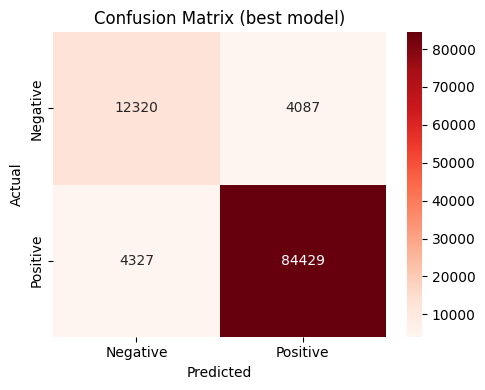

Most negative words: ['refund', 'worst', 'inedible', 'disappointing', 'disappointment', 'yuck', 'disgusting', 'threw', 'return', 'awful', 'byproduct', 'misleading', 'stupid', 'fda', 'rancid', 'ruined', 'terrible', 'horrible', 'garbage', 'unfortunate']
Most positive words: ['relax', 'hooked', 'pleasantly', 'addicting', 'guilt', 'pickmeup', 'gobbles', 'delish', 'beat', 'downside', 'yum', 'cravings', 'soothing', 'calm', 'goto', 'salads', 'satisfies', 'divine', 'perfect', 'skeptical']


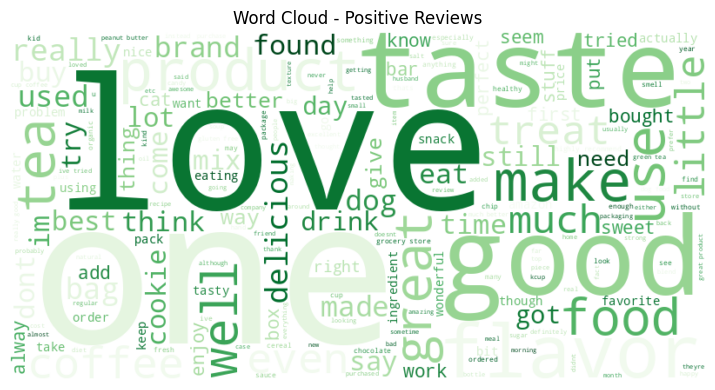

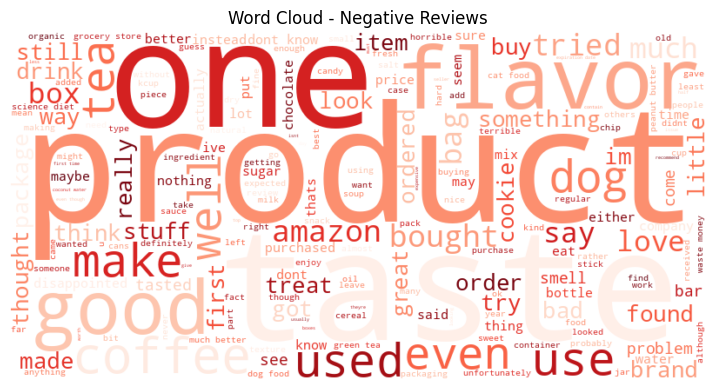

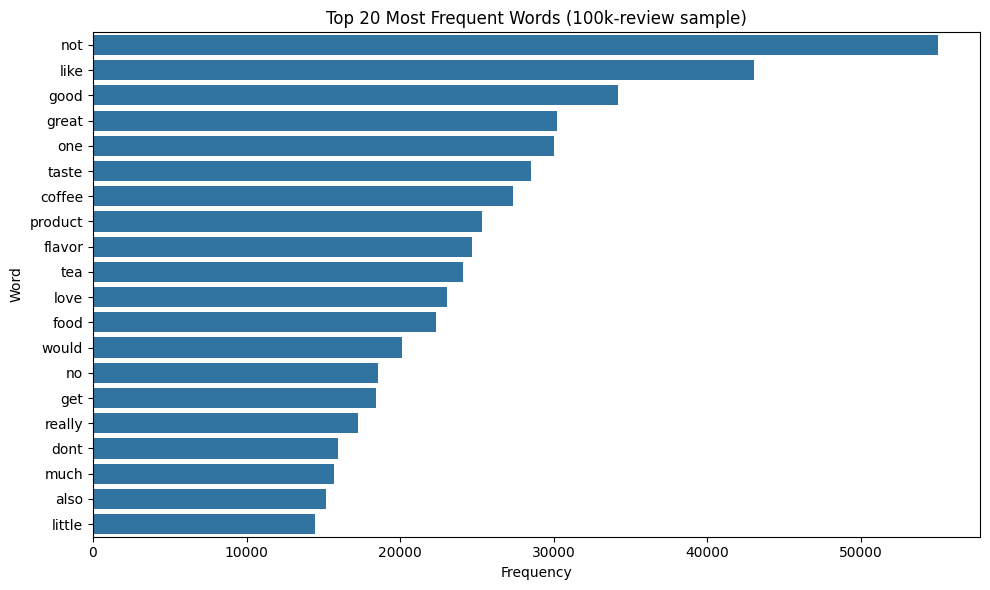

Negative
Positive


In [4]:
# %% [markdown]

# %% Imports
import os
import string
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.corpus import stopwords
from wordcloud import WordCloud

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.naive_bayes import MultinomialNB, ComplementNB
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    accuracy_score, f1_score, recall_score, roc_auc_score,
    confusion_matrix, classification_report,
)

nltk.download("stopwords", quiet=True)

RANDOM_STATE = 42
DATA_PATH = "data/Reviews.csv"
os.makedirs("images", exist_ok=True)

# %% Load data
df = pd.read_csv(DATA_PATH, usecols=["Text", "Score"]).dropna()
print("Reviews loaded:", len(df))

# Remove neutral reviews (score 3), then label: 4-5 = positive (1), 1-2 = negative (0)
df = df[df["Score"] != 3].copy()
df["Sentiment"] = (df["Score"] > 3).astype(int)
print("After removing neutral reviews:", len(df))
print(df["Sentiment"].value_counts(normalize=True).rename({1: "positive", 0: "negative"}))

# %% Class distribution plot
plt.figure(figsize=(5, 4))
ax = sns.countplot(x="Sentiment", data=df, hue="Sentiment",
                   palette=["red", "green"], legend=False)
ax.set_xticks([0, 1])
ax.set_xticklabels(["Negative", "Positive"])
plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.savefig("images/sentiment_distribution.png", dpi=150)
plt.show()


# %% Text cleaning
import re

stop_words = set(stopwords.words("english")) - {"not", "no", "nor"}  # keep negations
punct_table = str.maketrans("", "", string.punctuation)


def clean_text(text: str) -> str:
    """Remove HTML tags, lowercase, remove punctuation, remove English stop words."""
    text = re.sub(r"<[^>]+>", " ", text)   # remove HTML tags like <br />
    text = text.lower().translate(punct_table)
    return " ".join(w for w in text.split() if w not in stop_words)


df["Clean_Text"] = df["Text"].apply(clean_text)
df[["Text", "Clean_Text"]].head()

# %% Train / test split (stratified, so both sets keep the same class ratio)
X_train, X_test, y_train, y_test = train_test_split(
    df["Clean_Text"], df["Sentiment"],
    test_size=0.2, random_state=RANDOM_STATE, stratify=df["Sentiment"],
)
print("Train:", len(X_train), "| Test:", len(X_test))

# %% Baseline: always predict "positive"
baseline_acc = (y_test == 1).mean()
print(f"Baseline (always positive) accuracy: {baseline_acc:.3f}")

# %% Helper to evaluate a fitted pipeline on the test set
results = []


def evaluate(name, pipe):
    pred = pipe.predict(X_test)
    proba = pipe.predict_proba(X_test)[:, 1]
    row = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Macro F1": f1_score(y_test, pred, average="macro"),
        "Negative recall": recall_score(y_test, pred, pos_label=0),
        "ROC-AUC": roc_auc_score(y_test, proba),
    }
    results.append(row)
    print(f"\n=== {name} ===")
    print(classification_report(y_test, pred, target_names=["Negative", "Positive"], digits=3))
    return pred


# %% Model 1: Bag of Words + Multinomial Naive Bayes (original model)
bow_nb = make_pipeline(CountVectorizer(), MultinomialNB())
bow_nb.fit(X_train, y_train)
pred_bow_nb = evaluate("BoW + MultinomialNB", bow_nb)

# %% Model 2: TF-IDF + Multinomial Naive Bayes
tfidf_nb = make_pipeline(TfidfVectorizer(), MultinomialNB())
tfidf_nb.fit(X_train, y_train)
evaluate("TF-IDF + MultinomialNB", tfidf_nb)

# %% Model 3: Bag of Words + Complement Naive Bayes (designed for imbalanced text)
bow_cnb = make_pipeline(CountVectorizer(), ComplementNB())
bow_cnb.fit(X_train, y_train)
evaluate("BoW + ComplementNB", bow_cnb)

# %% 5-fold cross-validation + alpha tuning (on a 100k sample of the training set for speed)
sample = X_train.sample(n=min(100_000, len(X_train)), random_state=RANDOM_STATE)
y_sample = y_train.loc[sample.index]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

alphas = [0.1, 0.5, 1.0]
cv_scores = {}
for clf_class in (MultinomialNB, ComplementNB):
    for a in alphas:
        pipe = make_pipeline(CountVectorizer(), clf_class(alpha=a))
        scores = cross_val_score(pipe, sample, y_sample, cv=cv, scoring="f1_macro", n_jobs=-1)
        cv_scores[(clf_class.__name__, a)] = scores.mean()
        print(f"{clf_class.__name__:15s} alpha={a:<4} macro-F1 (5-fold CV): "
              f"{scores.mean():.3f} +/- {scores.std():.3f}")

best_name, best_alpha = max(cv_scores, key=cv_scores.get)
print("\nBest by CV:", best_name, "alpha =", best_alpha)

# %% Refit the best configuration on the full training set and test it once
best_class = {"MultinomialNB": MultinomialNB, "ComplementNB": ComplementNB}[best_name]
best_model = make_pipeline(CountVectorizer(), best_class(alpha=best_alpha))
best_model.fit(X_train, y_train)
pred_best = evaluate(f"BoW + {best_name} (alpha={best_alpha}, CV-tuned)", best_model)

# %% Results table
results_df = pd.DataFrame(results).round(3)
baseline_row = pd.DataFrame([{
    "Model": "Always predict positive (baseline)",
    "Accuracy": round(baseline_acc, 3), "Macro F1": np.nan,
    "Negative recall": 0.0, "ROC-AUC": 0.5,
}])
results_df = pd.concat([baseline_row, results_df], ignore_index=True)
print(results_df.to_string(index=False))
results_df.to_csv("results.csv", index=False)

# %% Confusion matrix of the best model
cm = confusion_matrix(y_test, pred_best)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Reds",
            xticklabels=["Negative", "Positive"], yticklabels=["Negative", "Positive"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix (best model)")
plt.tight_layout()
plt.savefig("images/confusion_matrix.png", dpi=150)
plt.show()

# %% Most informative words per class (from the BoW + MultinomialNB model)
vec = bow_nb.named_steps["countvectorizer"]
nb = bow_nb.named_steps["multinomialnb"]
words = np.array(vec.get_feature_names_out())
# Higher value = word is more typical of positive than negative reviews
log_ratio = nb.feature_log_prob_[1] - nb.feature_log_prob_[0]
min_count = np.asarray(vec.transform(X_train).sum(axis=0)).ravel()
mask = min_count >= 500  # ignore very rare words
order = np.argsort(log_ratio[mask])
print("Most negative words:", list(words[mask][order[:20]]))
print("Most positive words:", list(words[mask][order[-20:]][::-1]))

# %% Word clouds
for label, name, cmap in [(1, "positive", "Greens"), (0, "negative", "Reds")]:
    text = " ".join(df.loc[df["Sentiment"] == label, "Clean_Text"].sample(
        n=min(50_000, (df["Sentiment"] == label).sum()), random_state=RANDOM_STATE))
    wc = WordCloud(width=800, height=400, background_color="white", colormap=cmap).generate(text)
    plt.figure(figsize=(8, 4))
    plt.imshow(wc, interpolation="bilinear")
    plt.axis("off")
    plt.title(f"Word Cloud - {name.capitalize()} Reviews")
    plt.tight_layout()
    plt.savefig(f"images/wordcloud_{name}.png", dpi=150)
    plt.show()

# %% Top 20 most frequent words
counts = Counter(" ".join(df["Clean_Text"].sample(n=100_000, random_state=RANDOM_STATE)).split())
labels, values = zip(*counts.most_common(20))
plt.figure(figsize=(10, 6))
sns.barplot(x=list(values), y=list(labels))
plt.title("Top 20 Most Frequent Words (100k-review sample)")
plt.xlabel("Frequency")
plt.ylabel("Word")
plt.tight_layout()
plt.savefig("images/top_words.png", dpi=150)
plt.show()


# %% Predict sentiment for new text
def predict_sentiment(text: str, model=best_model) -> str:
    return "Positive" if model.predict([clean_text(text)])[0] == 1 else "Negative"


print(predict_sentiment("Product is useless"))
print(predict_sentiment("Absolutely delicious, I will buy this again"))

In [5]:
import shutil
from google.colab import files

# Compress the images folder into a zip file
shutil.make_archive('images_results', 'zip', 'images')

# Download the zip file
files.download('images_results.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>